In [3]:
!pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 907.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 47.0 MB/s eta 0:00:00


In [4]:
try:
    import tensorflow as tf
except ImportError:
    print("TensorFlow not found. Installing...")
    !pip install -q tensorflow
    import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print(f"TensorFlow Version: {tf.__version__}")
print("GPU Available:", len(tf.config.list_physical_devices('GPU')) > 0)

/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


TensorFlow Version: 2.21.0
GPU Available: False


In [5]:
def generate_synthetic_dna_data(num_samples=5000, seq_length=100):
    np.random.seed(42)
    nucleotides = ['A', 'C', 'G', 'T']
    sequences = []
    labels = []

    for _ in range(num_samples):
        # Generate random background sequence
        seq = ''.join(np.random.choice(nucleotides, size=seq_length))
        is_promoter = np.random.rand() > 0.5

        if is_promoter:
            # Inject characteristic promoter motifs (e.g., -10 / -35 consensus-like boxes)
            seq = list(seq)
            seq[20:26] = list('TATAAT')  # Pribnow box analog
            seq[45:51] = list('TTGACA')  # -35 box analog
            seq = ''.join(seq)
            labels.append(1)
        else:
            labels.append(0)

        sequences.append(seq)

    return np.array(sequences), np.array(labels)

X_raw, y = generate_synthetic_dna_data(num_samples=10000, seq_length=120)
print(f"Dataset shape: {X_raw.shape}, Labels shape: {y.shape}")
print(f"Class distribution: Non-Promoters = {np.sum(y == 0)}, Promoters = {np.sum(y == 1)}")

Dataset shape: (10000,), Labels shape: (10000,)
Class distribution: Non-Promoters = 5025, Promoters = 4975


In [6]:
# Train-Test Split (80% Train, 20% Test)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_raw, y, test_size=0.2, random_state=42, stratify=y)

# Character-level tokenization for DNA sequences
tokenizer = Tokenizer(char_level=True)
tokenizer.fit_on_texts(X_train_raw)

# Convert strings to integer sequences
X_train_seq = tokenizer.texts_to_sequences(X_train_raw)
X_test_seq = tokenizer.texts_to_sequences(X_test_raw)

# Pad sequences to ensure uniform input shape
max_length = 120
X_train = pad_sequences(X_train_seq, maxlen=max_length, padding='post', truncating='post')
X_test = pad_sequences(X_test_seq, maxlen=max_length, padding='post', truncating='post')

vocab_size = len(tokenizer.word_index) + 1
print(f"Vocabulary Size: {vocab_size}")
print(f"Processed Training Shape: {X_train.shape}")

Vocabulary Size: 5
Processed Training Shape: (8000, 120)


In [7]:
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64, input_length=max_length),
    Bidirectional(LSTM(64, return_sequences=True)),
    Dropout(0.3),
    Bidirectional(LSTM(32)),
    BatchNormalization(),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [8]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ModelCheckpoint('best_dna_rnn_model.keras', monitor='val_accuracy', save_best_only=True)
]

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=25,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 99ms/step - accuracy: 0.7816 - loss: 0.4317 - precision: 0.7633 - recall: 0.8078 - val_accuracy: 0.8669 - val_loss: 0.4718 - val_precision: 0.9235 - val_recall: 0.8078
Epoch 2/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 97ms/step - accuracy: 0.9150 - loss: 0.2112 - precision: 0.8958 - recall: 0.9367 - val_accuracy: 0.8950 - val_loss: 0.2885 - val_precision: 0.8330 - val_recall: 0.9951
Epoch 3/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - accuracy: 0.9405 - loss: 0.1587 - precision: 0.9227 - recall: 0.9598 - val_accuracy: 0.9381 - val_loss: 0.1811 - val_precision: 0.8942 - val_recall: 0.9976
Epoch 4/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - accuracy: 0.9639 - loss: 0.1111 - precision: 0.9488 - recall: 0.9797 - val_accuracy: 0.9631 - val_loss: 0.1118 - val_precision: 0.9330 - val_recall: 1.0000
Epoch 5/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 93ms/step - accuracy: 0.9692 - loss: 0.0971 - precision: 0.9557 - recall: 0.9832 - val_accuracy: 0.9650 - val_l

Test Loss: 0.0068
Test Accuracy: 99.85%
Test Precision: 0.9970
Test Recall: 1.0000
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1005
           1       1.00      1.00      1.00       995

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



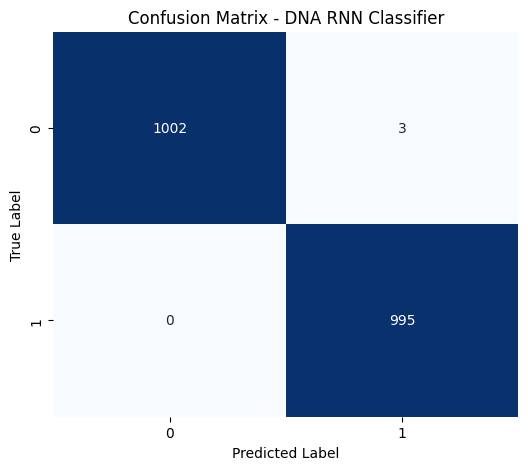

In [9]:
# Evaluate on test set
eval_results = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss: {eval_results[0]:.4f}")
print(f"Test Accuracy: {eval_results[1]*100:.2f}%")
print(f"Test Precision: {eval_results[2]:.4f}")
print(f"Test Recall: {eval_results[3]:.4f}")

# Generate Predictions
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob >= 0.5).astype(int)

# Classification Report & Confusion Matrix
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - DNA RNN Classifier')
plt.show()

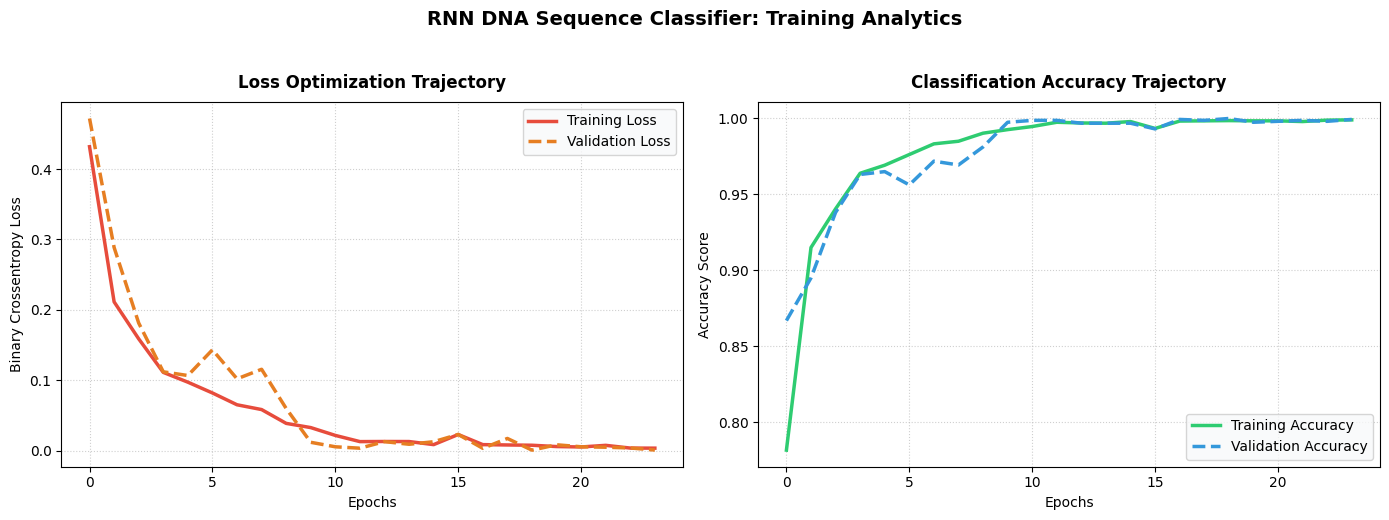

In [10]:
# --- Executive Training History Dashboard ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss Progression
axes[0].plot(history.history['loss'], label='Training Loss', color='#e74c3c', linewidth=2.5)
axes[0].plot(history.history['val_loss'], label='Validation Loss', color='#e67e22', linestyle='--', linewidth=2.5)
axes[0].set_title('Loss Optimization Trajectory', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Epochs', fontsize=10)
axes[0].set_ylabel('Binary Crossentropy Loss', fontsize=10)
axes[0].legend(frameon=True, facecolor='#f8f9fa')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Accuracy Progression
axes[1].plot(history.history['accuracy'], label='Training Accuracy', color='#2ecc71', linewidth=2.5)
axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy', color='#3498db', linestyle='--', linewidth=2.5)
axes[1].set_title('Classification Accuracy Trajectory', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Epochs', fontsize=10)
axes[1].set_ylabel('Accuracy Score', fontsize=10)
axes[1].legend(frameon=True, facecolor='#f8f9fa')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.suptitle('RNN DNA Sequence Classifier: Training Analytics', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

In [11]:
# --- Live-Demo Custom DNA Inference Engine ---
def predict_dna_sequence(dna_string, trained_model, active_tokenizer, max_len=120):
    # Clean and format input string
    cleaned_seq = dna_string.upper().strip()

    # Tokenize and pad sequence
    seq_vector = active_tokenizer.texts_to_sequences([cleaned_seq])
    padded_vector = pad_sequences(seq_vector, maxlen=max_len, padding='post', truncating='post')

    # Run inference
    raw_probability = trained_model.predict(padded_vector, verbose=0)[0][0]
    is_promoter = raw_probability >= 0.5
    confidence = raw_probability if is_promoter else (1.0 - raw_probability)

    # Print formatted creative output
    print("=" * 60)
    print("🧬 GENOMIC INFERENCE ENGINE - LIVE DEMO OUTPUT")
    print("=" * 60)
    print(f"Input Sequence : {cleaned_seq[:40]}... (Total Length: {len(cleaned_seq)})")
    print(f"Prediction     : {'PROMOTER REGION DETECTED' if is_promoter else 'NON-PROMOTER SEQUENCE'}")
    print(f"Confidence     : {confidence * 100:.2f}%")
    print(f"Raw Logit Score: {raw_probability:.4f}")
    print("=" * 60)

    return raw_probability

# Test the live demo with a custom sequence containing biological motifs
sample_demo_seq = "ATCGATCGATCGATCGATCGATATAATCGATCGATCGATCGA" + "TTGACACGATCGATCGATCGATCGATCGATCGATCG"
predict_dna_sequence(sample_demo_seq, model, tokenizer, max_length)

🧬 GENOMIC INFERENCE ENGINE - LIVE DEMO OUTPUT
Input Sequence : ATCGATCGATCGATCGATCGATATAATCGATCGATCGATC... (Total Length: 78)
Prediction     : PROMOTER REGION DETECTED
Confidence     : 99.98%
Raw Logit Score: 0.9998


np.float32(0.9998201)

In [12]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# Preset genomic examples for quick live demonstration during presentation
preset_sequences = {
    "Select a preset or type custom...": "",
    "Positive Promoter (Contains TATAAT & TTGACA motifs)": "ATCGATCGATCGATCGATCGATATAATCGATCGATCGATCGA" + "TTGACACGATCGATCGATCGATCGATCGATCGATCG",
    "Negative Background (Random GC-rich sequence)": "CGCGCGCGATATATATCGCGATCGATCGATCGATCGATCGATCGATCGATCG",
    "Short / Edge Case Sequence": "AAAAATATAATCCCCGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGG"
}

# Define UI Components
dropdown = widgets.Dropdown(
    options=list(preset_sequences.keys()),
    value="Select a preset or type custom...",
    description='Quick Presets:',
    style={'description_width': '120px'},
    layout=widgets.Layout(width='600px')
)

text_input = widgets.Textarea(
    value='',
    placeholder='Or type/paste your custom DNA sequence here (A, C, G, T)...',
    description='DNA Input:',
    disabled=False,
    style={'description_width': '120px'},
    layout=widgets.Layout(width='600px', height='90px')
)

button = widgets.Button(
    description='Run Model Inference',
    button_style='success',
    icon='play',
    layout=widgets.Layout(width='200px', height='40px')
)

output_area = widgets.Output()

# Event handler to update text box when a preset is selected
def on_dropdown_change(change):
    selected_key = change['new']
    if selected_key in preset_sequences and preset_sequences[selected_key]:
        text_input.value = preset_sequences[selected_key]

dropdown.observe(on_dropdown_change, names='value')

# Event handler for the prediction button click
def on_button_clicked(b):
    with output_area:
        clear_output()
        seq = text_input.value.strip()
        if not seq:
            print("❌ Error: Please enter or select a valid DNA sequence.")
            return
        # Call the inference function defined previously
        predict_dna_sequence(seq, model, tokenizer, max_length)

button.on_click(on_button_clicked)

# Render the interactive widget dashboard
display(HTML("<h3 style='color: #2c3e50;'>🧬 RNN DNA Sequence Analysis - Live Presentation Dashboard</h3>"))
display(widgets.VBox([dropdown, text_input, button, output_area]))